In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_csv("../data/processed/clean_sales.csv")

print(df.shape)
print(df.head())

(9994, 27)
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688  2016-06-12         NaN    Second Class    DV-13045   
3       4  US-2015-108966  2015-10-11         NaN  Standard Class    SO-20335   
4       5  US-2015-108966  2015-10-11         NaN  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...     Sales  \
0      Claire Gute   Consumer  United States        Henderson  ...  261.9600   
1      Claire Gute   Consumer  United States        Henderson  ...  731.9400   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   14.6200   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...  957.5775   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   22.3680   

   Quantity Discount 

In [4]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year', 'Month', 'Quarter', 'Weekday', 'Profit Margin', 'Sales Category']


In [5]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [6]:
print(df["Order Date"].min())
print(df["Order Date"].max())

2014-01-03 00:00:00
2017-12-11 00:00:00


In [7]:
reference_date = df["Order Date"].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)

Reference Date: 2017-12-12 00:00:00


In [8]:
rfm = df.groupby("Customer Name").agg({
    "Order Date": lambda x: (reference_date - x.max()).days,
    "Order ID": "nunique",
    "Sales": "sum"
})

In [9]:
rfm.columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

In [10]:
print(rfm.head())

                 Recency  Frequency  Monetary
Customer Name                                
Aaron Bergman      397.0          3   886.156
Aaron Hawkins        NaN          7  1744.700
Aaron Smayling      70.0          7  3050.692
Adam Bellavance     36.0          8  7755.620
Adam Hart            NaN         10  3250.337


In [11]:
print(rfm.describe())

           Recency   Frequency      Monetary
count   738.000000  793.000000    793.000000
mean    323.170732    6.316520   2896.848500
std     344.525943    2.550885   2628.670117
min       1.000000    1.000000      4.833000
25%      39.250000    5.000000   1146.050000
50%     186.500000    6.000000   2256.394000
75%     491.000000    8.000000   3785.276000
max    1436.000000   17.000000  25043.050000


Check distributions

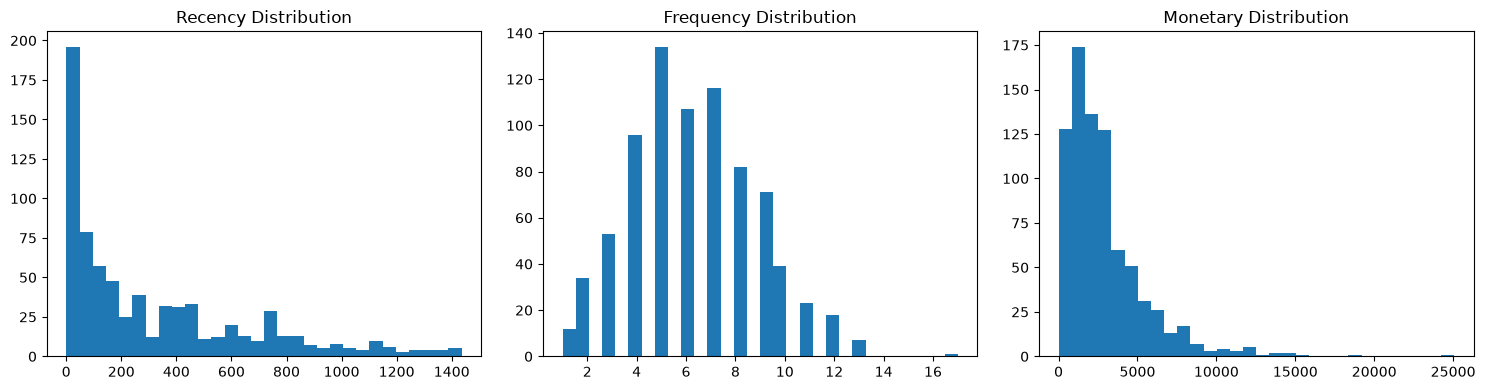

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(rfm["Recency"], bins=30)
axes[0].set_title("Recency Distribution")

axes[1].hist(rfm["Frequency"], bins=30)
axes[1].set_title("Frequency Distribution")

axes[2].hist(rfm["Monetary"], bins=30)
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()

In [13]:
rfm_log = np.log1p(rfm)
print(rfm_log.head())

                  Recency  Frequency  Monetary
Customer Name                                 
Aaron Bergman    5.986452   1.386294  6.788021
Aaron Hawkins         NaN   2.079442  7.464911
Aaron Smayling   4.262680   2.079442  8.023451
Adam Bellavance  3.610918   2.197225  8.956302
Adam Hart             NaN   2.397895  8.086822


In [14]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

In [15]:
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    index=rfm.index,
    columns=rfm.columns
)

print(rfm_scaled.head())

                  Recency  Frequency  Monetary
Customer Name                                 
Aaron Bergman    0.658882  -1.406241 -0.735599
Aaron Hawkins         NaN   0.409496 -0.090776
Aaron Smayling  -0.385590   0.409496  0.441304
Adam Bellavance -0.780507   0.718035  1.329962
Adam Hart             NaN   1.243703  0.501672


In [16]:
# Remove rows containing missing RFM values
rfm_clean = rfm.dropna().copy()

print("Original shape:", rfm.shape)
print("Clean shape:", rfm_clean.shape)

print("\nMissing values after cleaning:")
print(rfm_clean.isnull().sum())

Original shape: (793, 3)
Clean shape: (738, 3)

Missing values after cleaning:
Recency      0
Frequency    0
Monetary     0
dtype: int64


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_clean[["Recency", "Frequency", "Monetary"]]
)

print("NaN values:", np.isnan(rfm_scaled).sum())

NaN values: 0


In [18]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia.append(kmeans.inertia_)

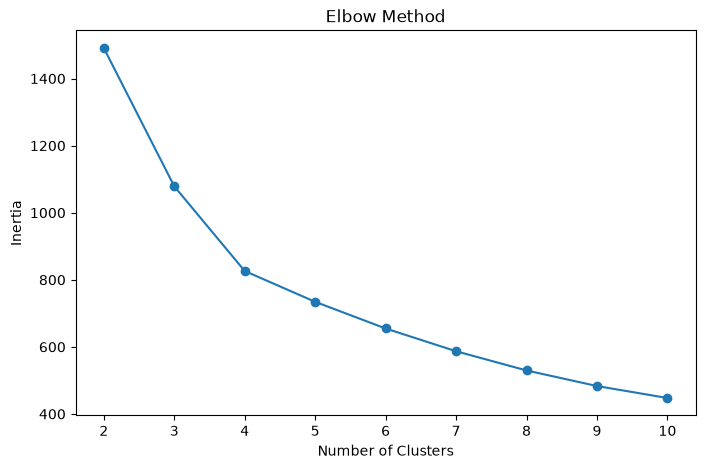

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

Silhouette Score

In [20]:
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    silhouette_scores.append(score)

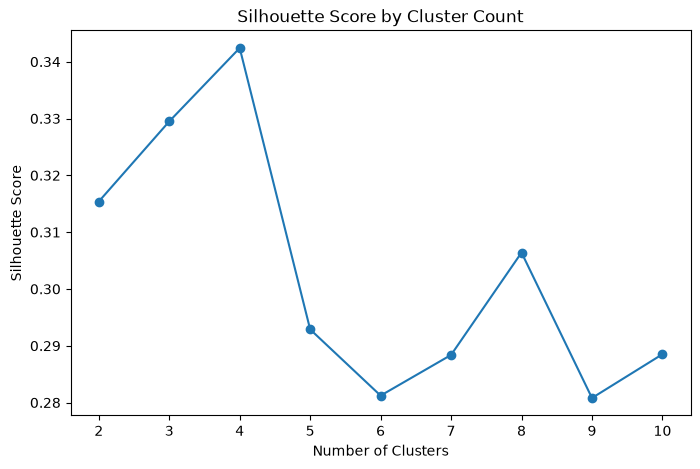

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Cluster Count")

plt.show()

In [41]:
rfm_clean = rfm.dropna(
    subset=["Recency", "Frequency", "Monetary"]
).copy()

In [42]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Remove missing RFM values
rfm_clean = rfm.dropna(
    subset=["Recency", "Frequency", "Monetary"]
).copy()

# Select RFM features
rfm_features = rfm_clean[
    ["Recency", "Frequency", "Monetary"]
]

# Scale the data
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_features)

# Create K-Means model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Create cluster labels
rfm_clean["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Check
print(rfm_clean.head())

print("\nCluster counts:")
print(rfm_clean["Cluster"].value_counts().sort_index())

                    Recency  Frequency   Monetary  Cluster
Customer Name                                             
Aaron Bergman         397.0          3    886.156        0
Aaron Smayling         70.0          7   3050.692        3
Adam Bellavance        36.0          8   7755.620        2
Adam Shillingsburg     10.0          9   3255.310        3
Adrian Barton         131.0         10  14473.571        2

Cluster counts:
Cluster
0    263
1    160
2     55
3    260
Name: count, dtype: int64


In [43]:
cluster_summary = rfm_clean.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

print("\nCluster Summary:")
print(cluster_summary)


Cluster Summary:
         Recency  Frequency  Monetary
Cluster                              
0         183.71       4.73   1651.39
1         873.69       5.30   2178.61
2         218.33       8.36   9843.05
3         147.64       8.67   3420.36


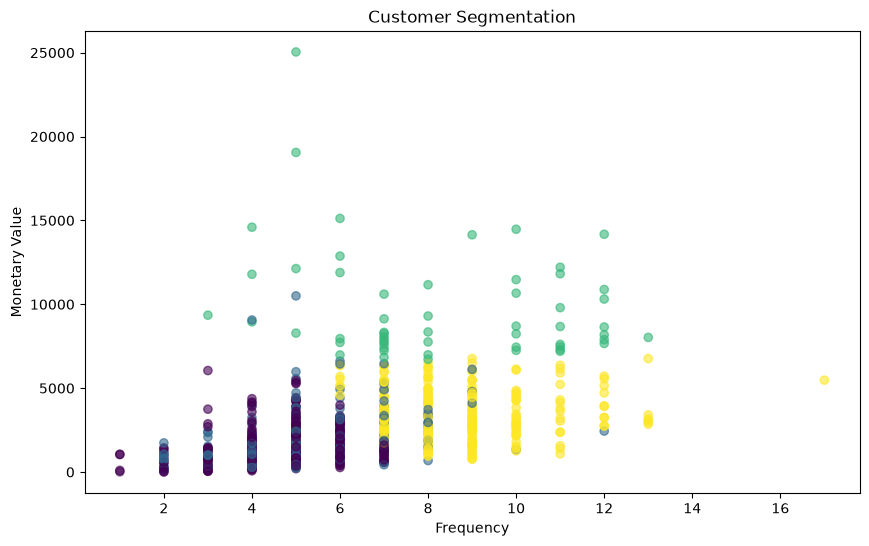

In [44]:
plt.figure(figsize=(10, 6))

plt.scatter(
    rfm_clean["Frequency"],
    rfm_clean["Monetary"],
    c=rfm_clean["Cluster"],
    alpha=0.6
)

plt.xlabel("Frequency")
plt.ylabel("Monetary Value")
plt.title("Customer Segmentation")

plt.show()

In [45]:
# Add business-friendly segment names

def assign_segment(cluster):

    if cluster == 1:
        return "At Risk"

    elif cluster == 2:
        return "High Value"

    elif cluster == 3:
        return "Loyal"

    else:
        return "Other"


# Apply segment names
rfm_clean["Segment"] = rfm_clean["Cluster"].apply(assign_segment)


# Create final customer segmentation table
customer_segments = rfm_clean.reset_index()[
    [
        "Customer Name",
        "Recency",
        "Frequency",
        "Monetary",
        "Cluster",
        "Segment"
    ]
]


# Display
print(
    customer_segments.head(20).to_string(index=False)
)

       Customer Name  Recency  Frequency  Monetary  Cluster    Segment
       Aaron Bergman    397.0          3   886.156        0      Other
      Aaron Smayling     70.0          7  3050.692        3      Loyal
     Adam Bellavance     36.0          8  7755.620        2 High Value
  Adam Shillingsburg     10.0          9  3255.310        3      Loyal
       Adrian Barton    131.0         10 14473.571        2 High Value
         Adrian Hane    163.0          7  1735.514        0      Other
         Aimee Bixby     99.0          5   966.710        0      Other
         Alan Barnes      7.0          8  1113.838        3      Loyal
      Alan Dominguez     11.0          8  6106.880        3      Loyal
         Alan Haines     37.0          4  1587.452        0      Other
          Alan Hwang    101.0          9  4805.344        3      Loyal
   Alan Schoenberger      4.0          5  4260.784        0      Other
        Alan Shonely    614.0          7   584.608        1    At Risk
Alejan

In [33]:
import os

os.makedirs("../data/ml", exist_ok=True)

In [47]:
customer_segments.to_csv(
    "../data/ml/customer_segments.csv",
    index=False
)

print("Customer segmentation dataset saved successfully!")

Customer segmentation dataset saved successfully!


In [48]:
import joblib

joblib.dump(
    scaler,
    "../models/rfm_scaler.pkl"
)

joblib.dump(
    kmeans,
    "../models/customer_segmentation_model.pkl"
)

['../models/customer_segmentation_model.pkl']